# Final Analytical Notebook – Executive Decision Report
**Author:** YOUR NAME  |  **Date:** DD-MM-YYYY

**NOTE: this kit ships with a SYNTHETIC sample dataset (`data/sample_sales_data.csv`). Replace it with your own data before submitting.**

**How to use:** (1) Put your CSV in the same folder (or upload in Colab) and set `DATA_PATH` and the column names in the *Config* cell. (2) If no file is found, the notebook runs on **synthetic demo data** so you can see it work. (3) Edit the markdown *Insight* cells with your own findings. (4) Kernel → Restart & Run All. Charts save to `charts/` for your slides.

## 1. Business Problem & Objectives
Write 3-4 lines: what decision must leadership make? e.g. *Which regions/products should we invest in to grow profit 10% next year, and where are we losing margin?*

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt, seaborn as sns
os.makedirs('charts', exist_ok=True)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=110

# ---- CONFIG: edit to match your dataset ----
DATA_PATH = 'data/sample_sales_data.csv'  # <- replace with your own CSV
COL = dict(date='Order Date', region='Region', category='Category', customer='Customer ID',
           sales='Sales', profit='Profit', discount='Discount', qty='Quantity')


## 2. Data Loading & Cleaning

In [2]:
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH, encoding='latin1'); print('Loaded', DATA_PATH)
else:
    print('data.csv not found -> using SYNTHETIC DEMO DATA'); rng=np.random.default_rng(7); n=4000
    df = pd.DataFrame({COL['date']: pd.to_datetime('2023-01-01')+pd.to_timedelta(rng.integers(0,1095,n),unit='D'),
        COL['region']: rng.choice(['North','South','East','West'],n,p=[.2,.35,.25,.2]),
        COL['category']: rng.choice(['Technology','Furniture','Office Supplies'],n,p=[.25,.25,.5]),
        COL['customer']: rng.integers(1,700,n), COL['qty']: rng.integers(1,8,n),
        COL['discount']: rng.choice([0,.1,.2,.3,.4],n,p=[.4,.2,.2,.1,.1])})
    base=rng.gamma(2,120,n); df[COL['sales']]=(base*df[COL['qty']]*(1-df[COL['discount']])).round(2)
    df[COL['profit']]=(df[COL['sales']]*(0.28-1.0*df[COL['discount']])+rng.normal(0,15,n)).round(2)
print(df.shape); df.head()

Loaded data/sample_sales_data.csv
(4000, 8)


,Order Date,Region,Category,Customer ID,Quantity,Discount,Sales,Profit
0,2023-01-01,South,Furniture,533,7,0.0,1192.20,345.96
1,2023-01-01,North,Office Supplies,372,7,0.1,1185.84,229.03
2,2023-01-01,West,Furniture,451,3,0.3,98.74,9.74
3,2023-01-02,South,Office Supplies,367,1,0.0,92.84,42.23
4,2023-01-03,North,Office Supplies,626,1,0.0,192.64,50.56


In [3]:
df = df.drop_duplicates()
df[COL['date']] = pd.to_datetime(df[COL['date']], errors='coerce')
print('Missing values:\n', df.isna().sum()[df.isna().sum()>0])
df = df.dropna(subset=[COL['date'], COL['sales'], COL['profit']])
df['Year']=df[COL['date']].dt.year; df['Month']=df[COL['date']].dt.to_period('M').dt.to_timestamp()
df['Margin %']=df[COL['profit']]/df[COL['sales']]*100
print('Rows after cleaning:', len(df), '| Period:', df[COL['date']].min().date(), 'to', df[COL['date']].max().date())

Missing values:
 Series([], dtype: int64)
Rows after cleaning: 4000 | Period: 2023-01-01 to 2025-12-30


## 3. Business Performance Snapshot (headline KPIs)

In [4]:
S,P,D=COL['sales'],COL['profit'],COL['discount']
kpi = dict(Revenue=df[S].sum(), Profit=df[P].sum(), Margin=df[P].sum()/df[S].sum()*100,
           Orders=len(df), Customers=df[COL['customer']].nunique(), AvgDiscount=df[D].mean()*100)
for k,v in kpi.items(): print(f'{k:12s}: {v:,.2f}')
yr=df.groupby('Year')[[S,P]].sum(); yr['Revenue growth %']=yr[S].pct_change()*100; yr

Revenue     : 3,355,217.64
Profit      : 569,683.33
Margin      : 16.98
Orders      : 4,000.00
Customers   : 696.00
AvgDiscount : 13.16


,Sales,Profit,Revenue growth %
Year,,,
2023,1109096.52,191782.97,NaN
2024,1097619.40,181659.66,-1.034817
2025,1148501.72,196240.70,4.635698


## 4. Key Revenue Drivers

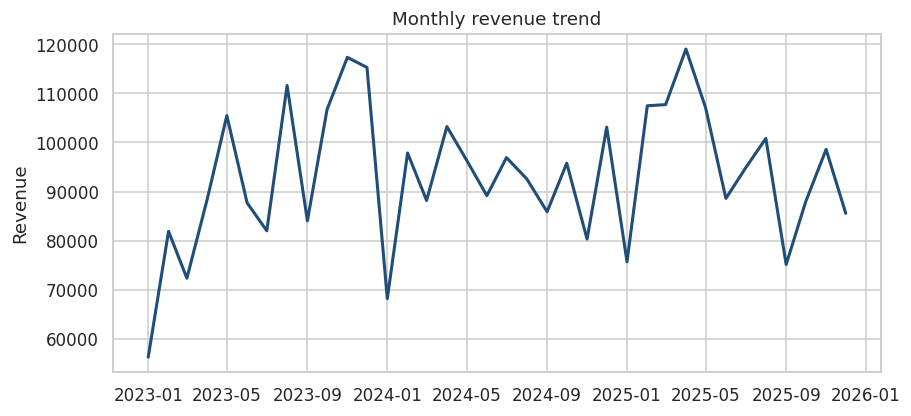

In [5]:
fig,ax=plt.subplots(figsize=(9,4)); m=df.groupby('Month')[S].sum(); ax.plot(m.index,m.values,color='#1F4E79',lw=2)
ax.set_title('Monthly revenue trend'); ax.set_ylabel('Revenue'); plt.savefig('charts/01_revenue_trend.png',dpi=200,bbox_inches='tight'); plt.show()

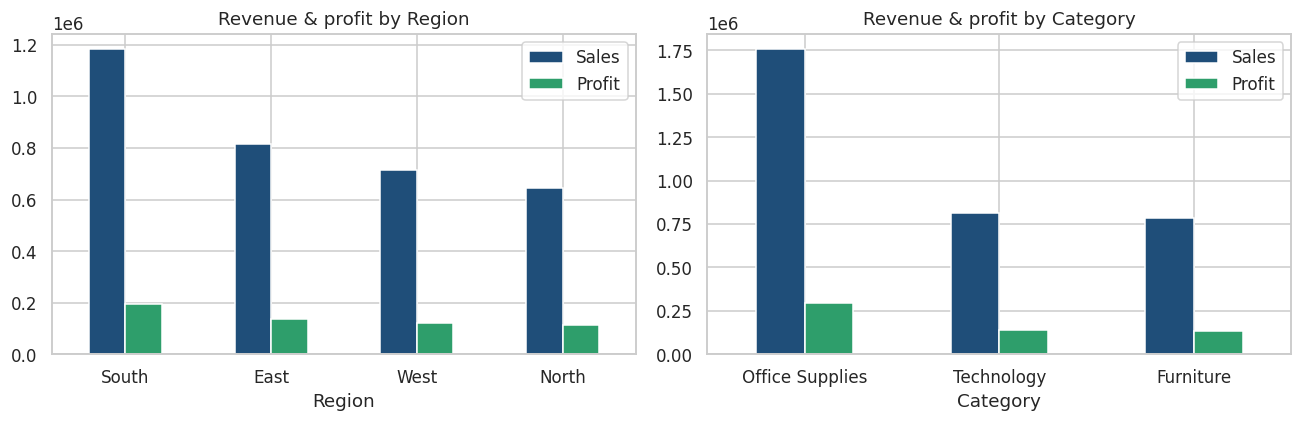

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axes,[COL['region'],COL['category']]):
    t=df.groupby(c)[[S,P]].sum().sort_values(S,ascending=False)
    t.plot(kind='bar',ax=ax,color=['#1F4E79','#2E9E6B']); ax.set_title(f'Revenue & profit by {c}'); ax.tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.savefig('charts/02_region_category.png',dpi=200,bbox_inches='tight'); plt.show()

In [7]:
# Revenue concentration: top 20% customers' share of revenue
cust=df.groupby(COL['customer'])[S].sum().sort_values(ascending=False)
top=cust.head(int(len(cust)*.2)).sum()/cust.sum()*100; print(f'Top 20% customers generate {top:.1f}% of revenue')

Top 20% customers generate 37.2% of revenue


**Insight 1 (edit):** *What happened → Why → So what?*  
**Insight 2 (edit):**  
**Insight 3 (edit):**

## 5. Risk Analysis

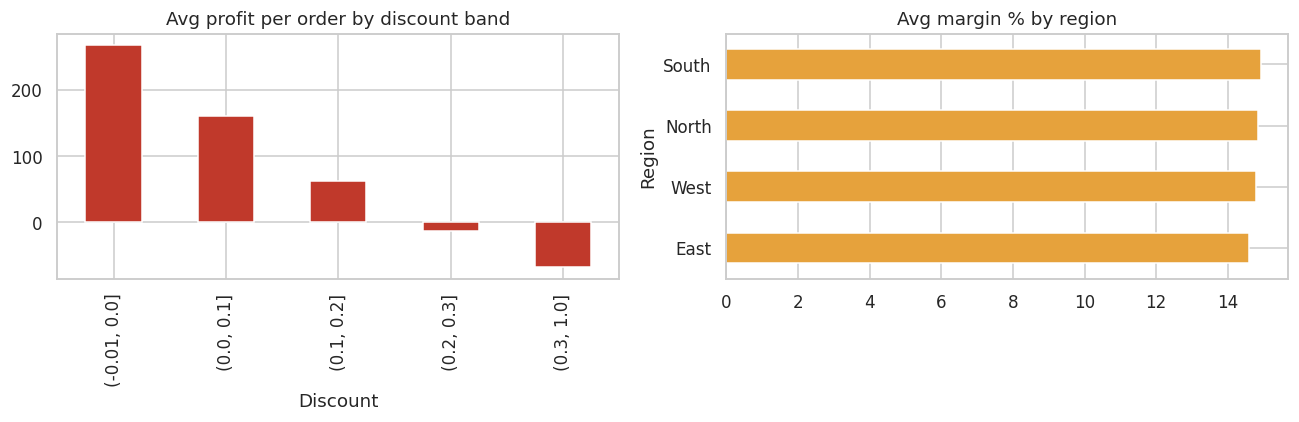

Loss-making orders: 19.5% | Profit lost: -34,645


In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
d=df.groupby(pd.cut(df[D],[-.01,0,.1,.2,.3,1]))[P].mean(); d.plot(kind='bar',ax=axes[0],color='#C0392B'); axes[0].set_title('Avg profit per order by discount band')
r=df.groupby(COL['region'])['Margin %'].mean().sort_values(); r.plot(kind='barh',ax=axes[1],color='#E6A23C'); axes[1].set_title('Avg margin % by region')
plt.tight_layout(); plt.savefig('charts/03_risks.png',dpi=200,bbox_inches='tight'); plt.show()
loss=df[df[P]<0]; print(f'Loss-making orders: {len(loss)/len(df)*100:.1f}% | Profit lost: {loss[P].sum():,.0f}')

**Risks to report (edit):** discount-driven margin leakage, regional/customer concentration, loss-making categories, data limitations.

## 6. Recommendations & ROI Projections
The numbers below are computed from your data; investment costs and uplift rates are **assumptions** – state them on the slide.

In [9]:
# --- Recommendation 1: cap discounts above 20% ---
high=df[df[D]>0.2]; r1_gain=-high[P][high[P]<0].sum()*0.5     # recover 50% of losses on deep-discount orders
# --- Recommendation 2: grow best region/category ---
best=df.groupby(COL['region'])[P].sum().idxmax(); r2_gain=df[df[COL['region']]==best][P].sum()*0.08
# --- Recommendation 3: retain top customers ---
r3_gain=cust.head(int(len(cust)*.2)).sum()*(df[P].sum()/df[S].sum())*0.05
inv=dict(R1=0.02*df[S].sum()*0.05, R2=0.04*df[S].sum()*0.05, R3=0.03*df[S].sum()*0.05)  # ASSUMED costs
rows=[]
for n,g,i in [('R1: Discount governance',r1_gain,inv['R1']),('R2: Scale best region',r2_gain,inv['R2']),('R3: Top-customer retention',r3_gain,inv['R3'])]:
    for sc,f in [('Conservative',.6),('Expected',1),('Optimistic',1.3)]:
        rows.append([n,sc,g*f,i,(g*f-i)/i*100,i/(g*f/12) if g>0 else np.nan])
roi=pd.DataFrame(rows,columns=['Recommendation','Scenario','Annual gain','Investment','ROI %','Payback (months)']).round(1); roi

,Recommendation,Scenario,Annual gain,Investment,ROI %,Payback (months)
0,R1: Discount governance,Conservative,10230.7,3355.2,204.9,3.9
1,R1: Discount governance,Expected,17051.2,3355.2,408.2,2.4
2,R1: Discount governance,Optimistic,22166.5,3355.2,560.7,1.8
3,R2: Scale best region,Conservative,9400.1,6710.4,40.1,8.6
4,R2: Scale best region,Expected,15666.9,6710.4,133.5,5.1
5,R2: Scale best region,Optimistic,20366.9,6710.4,203.5,4.0
6,R3: Top-customer retention,Conservative,6365.1,5032.8,26.5,9.5
7,R3: Top-customer retention,Expected,10608.4,5032.8,110.8,5.7
8,R3: Top-customer retention,Optimistic,13791.0,5032.8,174.0,4.4


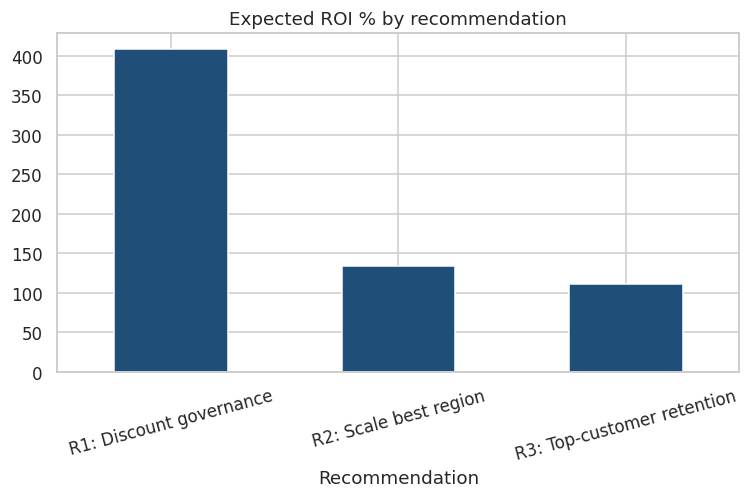

In [10]:
exp=roi[roi.Scenario=='Expected']; ax=exp.plot(x='Recommendation',y='ROI %',kind='bar',legend=False,color='#1F4E79',figsize=(8,4))
ax.set_title('Expected ROI % by recommendation'); plt.xticks(rotation=15); plt.savefig('charts/04_roi.png',dpi=200,bbox_inches='tight'); plt.show()
roi.to_csv('roi_scenarios.csv',index=False)

## 7. Implementation Timeline
| Phase | When | Activities | Owner | KPI |
|---|---|---|---|---|
| Pilot | Month 0-1 | Test in one segment | Ops lead | Lift vs baseline |
| Rollout | Month 2-4 | Scale to all regions | Business head | Revenue/margin |
| Optimize | Month 5-6 | Review & adjust | Analytics | ROI achieved |

## 8. Conclusion
Summarise in 3 lines: the key finding, the 3 actions, and total expected ROI. List assumptions and limitations.

In [11]:
import json
reg=df.groupby(COL['region'])[[S,P]].sum(); cat=df.groupby(COL['category'])[[S,P]].sum()
hi=df[df[D]>0.2]
json.dump(dict(kpi=kpi,yr=yr.reset_index().to_dict('list'),reg=reg.reset_index().to_dict('list'),cat=cat.reset_index().to_dict('list'),
 top20=float(top),loss_pct=float(len(loss)/len(df)*100),loss_amt=float(loss[P].sum()),
 hi_n=int(len(hi)),hi_profit=float(hi[P].sum()),hi_avgprofit=float(hi[P].mean()),best_region=best,
 roi=roi.to_dict('records'),inv=inv),open('metrics.json','w'),default=float,indent=1)
print('metrics saved')

metrics saved
